In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

!pip install -q kaggle tf-keras matplotlib scikit-learn pandas seaborn gdown pillow

import tensorflow as tf
import tf_keras

print("Active TF Version:", tf.__version__)
print("Active Keras Version:", tf_keras.__version__)

import json

Mounted at /content/drive
Active TF Version: 2.21.0
Active Keras Version: 2.21.0


In [2]:
import os
import json
import getpass

kaggle_username = input("Enter your Kaggle username: ")
kaggle_key = getpass.getpass("Enter your Kaggle API key: ")

kaggle_data = {
    "username": kaggle_username,
    "key": kaggle_key
}

os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
with open(os.path.expanduser("~/.kaggle/kaggle.json"), "w") as f:
    json.dump(kaggle_data, f)

!chmod 600 ~/.kaggle/kaggle.json

print("Testing connection to Kaggle...")
!kaggle datasets list -s caltech-101

Enter your Kaggle username: babakrommel
Enter your Kaggle API key: ··········
Testing connection to Kaggle...
ref                                                     title                                                   size  lastUpdated                 downloadCount  voteCount  usabilityRating  
------------------------------------------------------  ------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
imbikramsaha/caltech-101                                caltech-101 dataset                                137164484  2022-07-12 07:38:24.903000          12662         63  0.875            
jessicali9530/caltech256                                Caltech 256 Image Dataset                         2276599398  2018-06-06 03:18:49.730000          17778        240  0.75             
pradip11/caltech-101-csv                                Caltech 101 [csv]                                  256636743  2019-10-03 1

In [3]:
print("Downloading dataset...")
!kaggle datasets download -d imbikramsaha/caltech-101 -p /content/ --force

if os.path.exists("/content/caltech-101.zip"):
    print("Download successful! Extracting...")
    !mkdir -p /content/dataset
    !unzip -q /content/caltech-101.zip -d /content/dataset

    # Finding the exact path of the images (This part is very important)
    import glob
    found_dirs = glob.glob("/content/dataset/**/airplanes", recursive=True)
    if found_dirs:

        dataset_path = os.path.dirname(found_dirs[0])
        print(f"Real dataset path found: {dataset_path}")
    else:
        dataset_path = "/content/dataset"
        print("Warning: Could not find object folders. Check path.")
else:
    print("ERROR: Download failed. Check internet or Kaggle Key.")


import shutil
from pathlib import Path
from sklearn.model_selection import train_test_split


dataset_path = "/content/dataset/caltech-101"
base_dir = Path("/content/caltech_split")

# Cleanup to ensure images are copied again
if base_dir.exists():
    shutil.rmtree(base_dir)

train_dir = base_dir / "train"
val_dir = base_dir / "val"
os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)

print("Copying images to train/val folders... Please wait.")

# Counter for final check
total_copied = 0

for category in os.listdir(dataset_path):
    cat_path = os.path.join(dataset_path, category)
    if os.path.isdir(cat_path):
        # Find all images
        images = [os.path.join(cat_path, f) for f in os.listdir(cat_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

        # Remove very small classes for better accuracy
        if len(images) < 10:
            continue

        train_imgs, val_imgs = train_test_split(images, test_size=0.2, random_state=42)

        os.makedirs(train_dir / category, exist_ok=True)
        os.makedirs(val_dir / category, exist_ok=True)

        for img in train_imgs:
            shutil.copy(img, train_dir / category)
            total_copied += 1
        for img in val_imgs:
            shutil.copy(img, val_dir / category)
            total_copied += 1

print(f"Dataset split complete! Total images moved: {total_copied}")

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

train_datagen = ImageDataGenerator(rescale=1./255, rotation_range=25, width_shift_range=0.2,
                                   height_shift_range=0.2, zoom_range=0.2, horizontal_flip=True)
val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir, target_size=(224, 224), batch_size=32, class_mode='categorical'
)
val_gen = val_datagen.flow_from_directory(
    val_dir, target_size=(224, 224), batch_size=32, class_mode='categorical', shuffle=False
)

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224,224,3))

for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers[-30:]:
    layer.trainable = True

x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.4)(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)
out = Dense(train_gen.num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=out)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss='categorical_crossentropy', metrics=['accuracy'])

callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5)
]

history = model.fit(train_gen, validation_data=val_gen, epochs=70, callbacks=callbacks)
print("Model training complete!")

model_path = "/content/drive/MyDrive/final_model_caltech.h5"
mapping_path = "/content/drive/MyDrive/class_indices.json"

model.save(model_path)
with open(mapping_path, "w") as f:
    json.dump(train_gen.class_indices, f)

print("Model and class mapping saved to Google Drive.")

Dataset URL: https://www.kaggle.com/datasets/imbikramsaha/caltech-101
License(s): CC0-1.0
100% 131M/131M [00:01<00:00, 87.6MB/s]

Download successful! Extracting...
Real dataset path found: /content/dataset/caltech-101
Copying images to train/val folders... Please wait.
Dataset split complete! Total images moved: 9144
Found 7280 images belonging to 102 classes.
Found 1864 images belonging to 102 classes.
9406464/9406464 [==============================] - 0s 0us/step
Epoch 1/70
228/228 [==============================] - 124s 494ms/step - loss: 3.1119 - accuracy: 0.3530 - val_loss: 1.7744 - val_accuracy: 0.6245 - lr: 1.0000e-04
Epoch 2/70
228/228 [==============================] - 114s 500ms/step - loss: 1.5302 - accuracy: 0.6569 - val_loss: 0.6756 - val_accuracy: 0.8407 - lr: 1.0000e-04
Epoch 3/70
228/228 [==============================] - 116s 507ms/step - loss: 0.8643 - accuracy: 0.7846 - val_loss: 0.4281 - val_accuracy: 0.8820 - lr: 1.0000e-04
Epoch 4/70
228/228 [====================

/usr/local/lib/python3.13/dist-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Model and class mapping saved to Google Drive.


In [10]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
import random
import json
import os
from google.colab import files

# 1. Define a clear output folder on your Drive
output_folder = "/content/drive/MyDrive/Caltech_Final_Files"
os.makedirs(output_folder, exist_ok=True)

# 2. Define the paths
model_save_path = os.path.join(output_folder, "final_model_caltech.h5")
json_save_path = os.path.join(output_folder, "class_indices.json")

# 3. Save the model and JSON to Drive
print("💾 Saving files to Google Drive...")
model.save(model_save_path)
with open(json_save_path, "w") as f:
    json.dump(train_gen.class_indices, f)
print(f"✅ Saved to: {output_folder}")

# 4. Directly download to your local Computer (Browser download)
print("⬇️ Starting direct download to your PC...")
files.download(model_save_path)
files.download(json_save_path)

💾 Saving files to Google Drive...


/usr/local/lib/python3.13/dist-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


✅ Saved to: /content/drive/MyDrive/Caltech_Final_Files
⬇️ Starting direct download to your PC...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

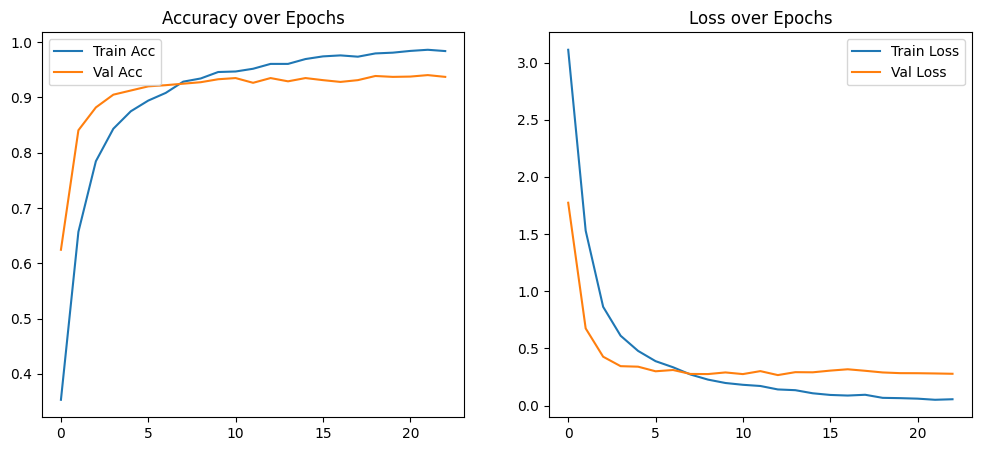

In [11]:

acc, val_acc = history.history['accuracy'], history.history['val_accuracy']
loss, val_loss = history.history['loss'], history.history['val_loss']

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(acc, label='Train Acc')
plt.plot(val_acc, label='Val Acc')
plt.title('Accuracy over Epochs')
plt.legend()

plt.subplot(1,2,2)
plt.plot(loss, label='Train Loss')
plt.plot(val_loss, label='Val Loss')
plt.title('Loss over Epochs')
plt.legend()
plt.show()


59/59 [==============================] - 5s 77ms/step


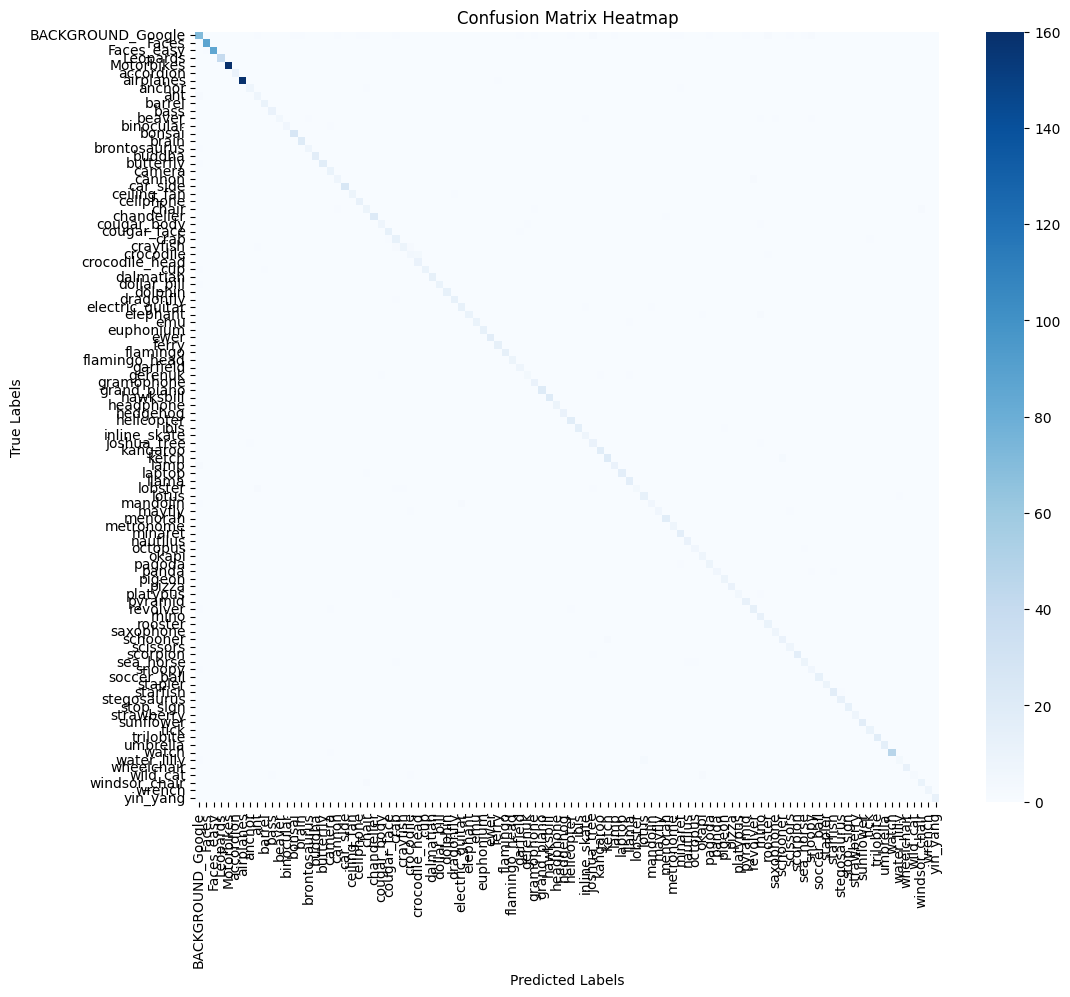

In [12]:
val_gen.reset()
y_pred = model.predict(val_gen, verbose=1)
y_true = val_gen.classes
y_pred_classes = np.argmax(y_pred, axis=1)
class_labels = list(val_gen.class_indices.keys())

cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
plt.title("Confusion Matrix Heatmap")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

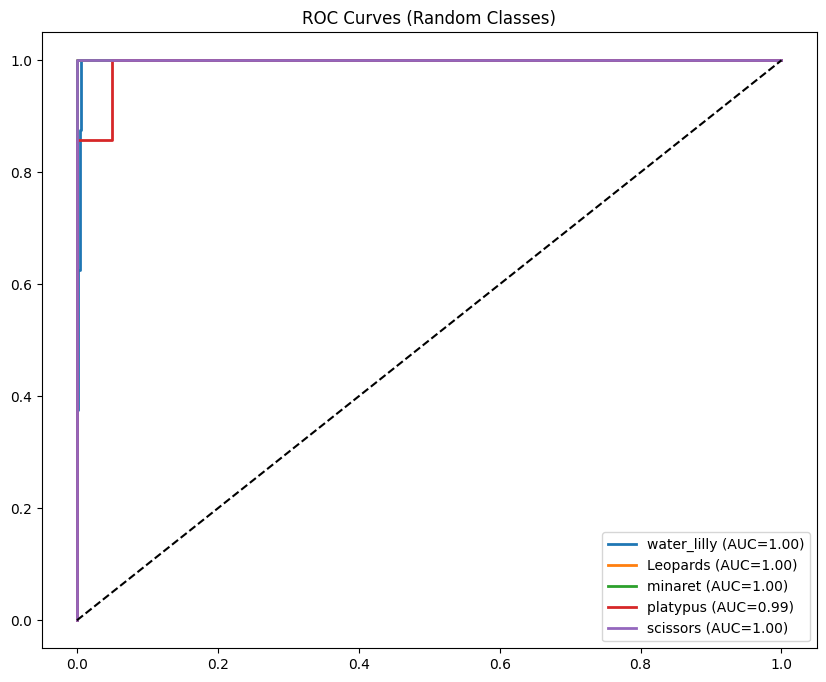

In [13]:
y_true_bin = label_binarize(y_true, classes=range(len(class_labels)))
random_classes = random.sample(class_labels, min(5, len(class_labels)))

plt.figure(figsize=(10, 8))
for label in random_classes:
    i = class_labels.index(label)
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
    plt.plot(fpr, tpr, lw=2, label=f'{label} (AUC={auc(fpr, tpr):.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curves (Random Classes)')
plt.legend()
plt.show()

1/1 [==============================] - 0s 45ms/step


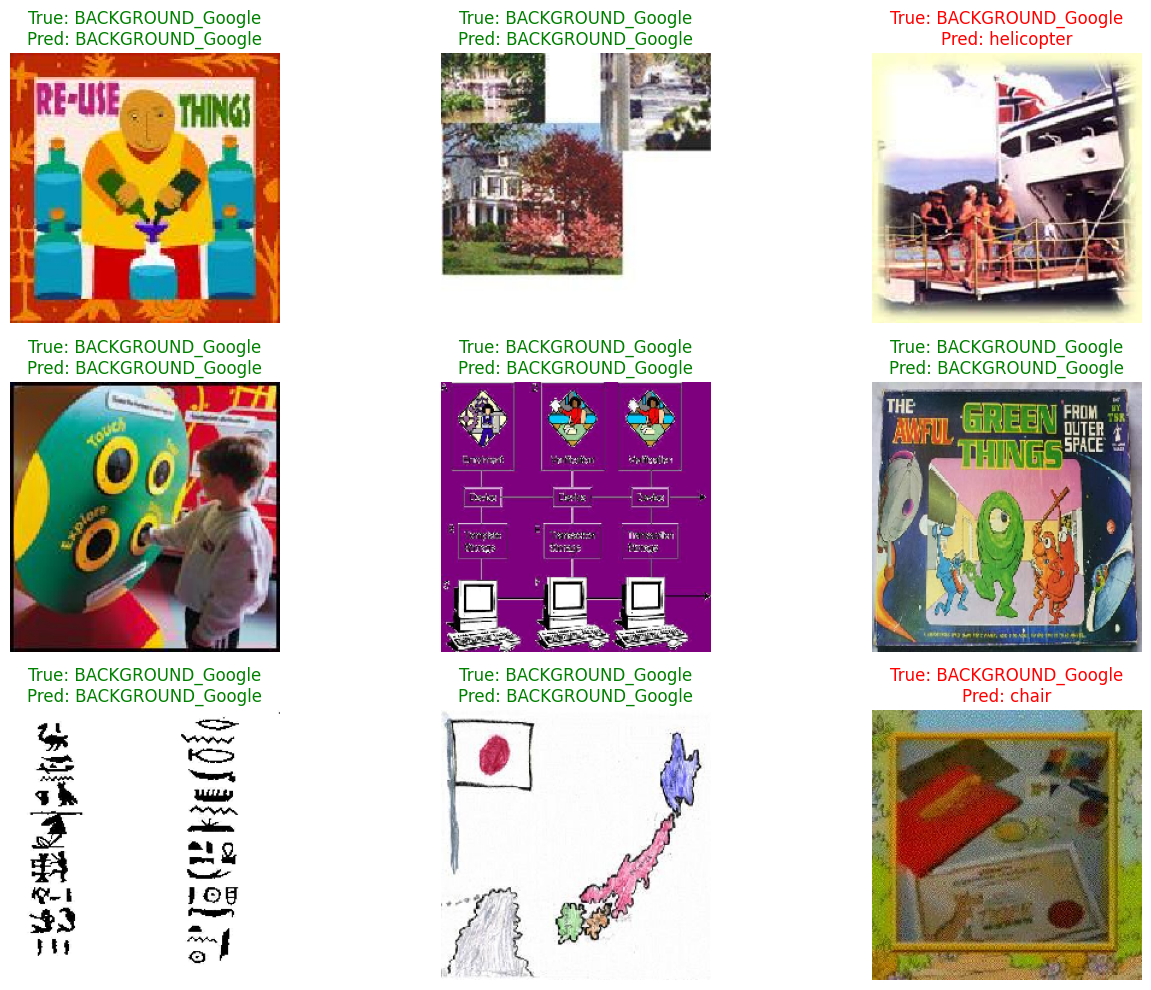

All evaluation visualizations complete!


In [14]:
val_gen.reset()
x_batch, y_batch = next(val_gen)
preds = model.predict(x_batch)
pred_classes = np.argmax(preds, axis=1)
true_classes = np.argmax(y_batch, axis=1)

plt.figure(figsize=(14, 10))
for i in range(min(9, len(x_batch))):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_batch[i])
    p_label = class_labels[pred_classes[i]]
    t_label = class_labels[true_classes[i]]
    color = "green" if p_label == t_label else "red"
    plt.title(f"True: {t_label}\nPred: {p_label}", color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()

print("All evaluation visualizations complete!")